<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Logistic_Regression/titanic_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print('Rows, columns:', df.shape)
print()
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Survival counts (0 = died, 1 = survived):')
print(df['Survived'].value_counts())
print()
print('Share who survived:', round(df['Survived'].mean(), 3))

Rows, columns: (891, 12)

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival counts (0 = died, 1 = survived):
Survived
0    549
1    342
Name: count, dtype: int64

Share who survived: 0.384


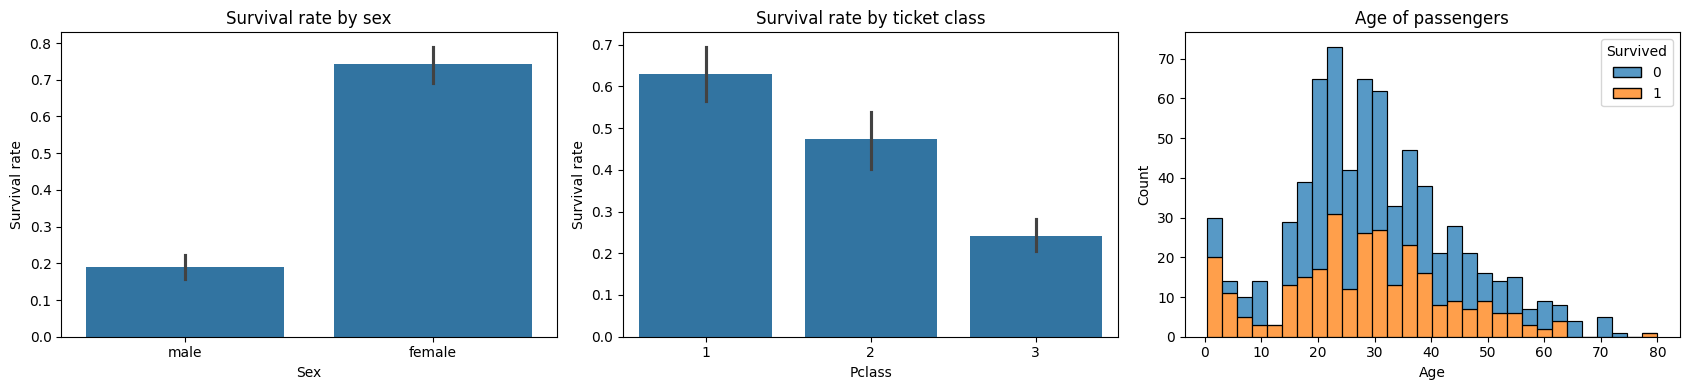

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0])
axes[0].set_title('Survival rate by sex')
axes[0].set_ylabel('Survival rate')

sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival rate by ticket class')
axes[1].set_ylabel('Survival rate')

sns.histplot(data=df, x='Age', hue='Survived', bins=30, multiple='stack', ax=axes[2])
axes[2].set_title('Age of passengers')

plt.tight_layout()
plt.show()

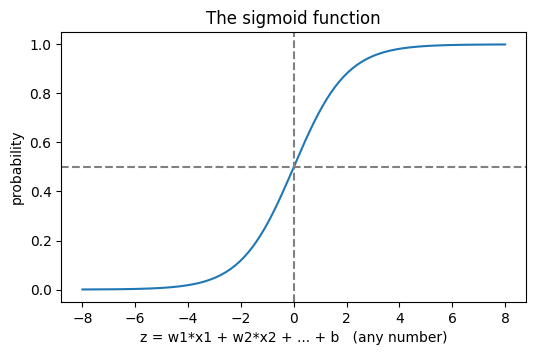

In [4]:
z = np.linspace(-8, 8, 200)
p = 1 / (1 + np.exp(-z))

plt.figure(figsize=(6, 3.5))
plt.plot(z, p)
plt.axhline(0.5, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('z = w1*x1 + w2*x2 + ... + b   (any number)')
plt.ylabel('probability')
plt.title('The sigmoid function')
plt.show()

In [5]:
data = df.copy()

# 1) fill the few missing ports with the most common one
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# 2) new features built from existing columns
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

# 3) drop IDs, free text, mostly-empty and now-redundant columns
data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'SibSp', 'Parch'])

# 4) text -> 0/1 columns
data = pd.get_dummies(data, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

X = data.drop(columns='Survived')   # features
y = data['Survived']                # label

print(X.columns.tolist())
X.head()

['Pclass', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S']


,Pclass,Age,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,7.2500,2,0,1,0,1
1,1,38.0,71.2833,2,0,0,0,0
2,3,26.0,7.9250,1,1,0,0,1
3,1,35.0,53.1000,2,0,0,0,1
4,3,35.0,8.0500,1,1,1,0,1


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# fill missing ages with the TRAINING median
X_train = X_train.copy()
X_test = X_test.copy()
age_median = X_train['Age'].median()
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

# scale the numeric columns (fit on training data only)
num_cols = ['Age', 'Fare', 'FamilySize']
scaler = StandardScaler().fit(X_train[num_cols])

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

print('Training rows:', len(X_train_s), '| Test rows:', len(X_test_s))
print('Missing values left in training features:', int(X_train_s.isnull().sum().sum()))

Training rows: 712 | Test rows: 179
Missing values left in training features: 0


In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_s, y_train)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

print('Training finished.')

Training finished.


Baseline accuracy (always say died): 0.615
Model accuracy (test)              : 0.793
Model accuracy (train)             : 0.805
ROC-AUC (test)                     : 0.846

              precision    recall  f1-score   support

        Died       0.82      0.85      0.84       110
    Survived       0.75      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



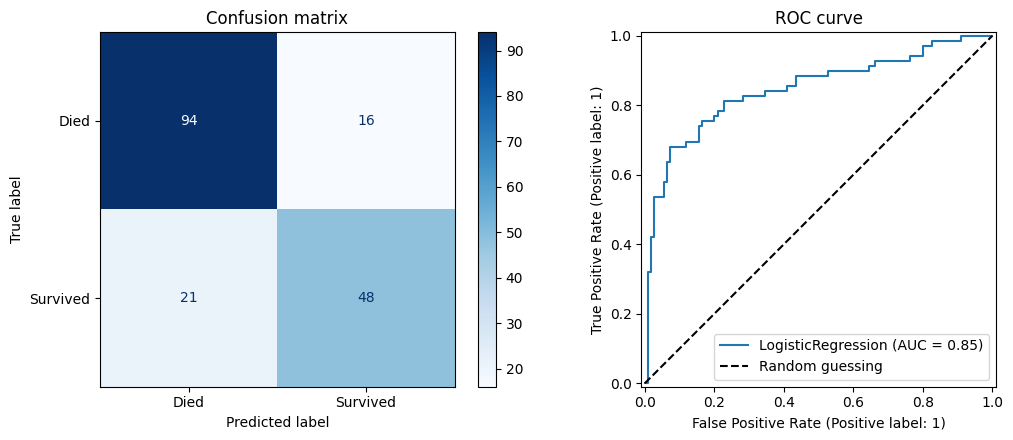

In [8]:
from sklearn.metrics import (accuracy_score, classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

pred = model.predict(X_test_s)                 # class labels (0 or 1)
proba = model.predict_proba(X_test_s)[:, 1]    # probability of survival

print('Baseline accuracy (always say died):', round(accuracy_score(y_test, baseline.predict(X_test_s)), 3))
print('Model accuracy (test)              :', round(accuracy_score(y_test, pred), 3))
print('Model accuracy (train)             :', round(model.score(X_train_s, y_train), 3))
print('ROC-AUC (test)                     :', round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, target_names=['Died', 'Survived']))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_estimator(
    model, X_test_s, y_test, display_labels=['Died', 'Survived'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion matrix')

RocCurveDisplay.from_estimator(model, X_test_s, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guessing')
axes[1].legend()
axes[1].set_title('ROC curve')

plt.tight_layout()
plt.show()

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

print('First 5 test passengers:')
show = pd.DataFrame({
    'actual': y_test.values[:5],
    'P(survived)': proba[:5].round(3),
    'predicted': pred[:5],
})
print(show.to_string(index=False))
print()

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p_t = (proba >= t).astype(int)
    rows.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, p_t),
        'precision': precision_score(y_test, p_t, zero_division=0),
        'recall': recall_score(y_test, p_t, zero_division=0),
        'f1': f1_score(y_test, p_t, zero_division=0),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

First 5 test passengers:
 actual  P(survived)  predicted
      0        0.102          0
      0        0.068          0
      1        0.143          0
      0        0.057          0
      1        0.754          1

 threshold  accuracy  precision  recall    f1
       0.3     0.771      0.667   0.812 0.732
       0.4     0.788      0.712   0.754 0.732
       0.5     0.793      0.750   0.696 0.722
       0.6     0.821      0.863   0.638 0.733
       0.7     0.788      0.919   0.493 0.642


Intercept: 3.951

   feature  coefficient  odds_ratio
  Sex_male       -2.512       0.081
    Pclass       -1.046       0.351
   IsAlone       -0.576       0.562
       Age       -0.473       0.623
FamilySize       -0.466       0.628
Embarked_S       -0.332       0.717
      Fare        0.096       1.101
Embarked_Q        0.334       1.397


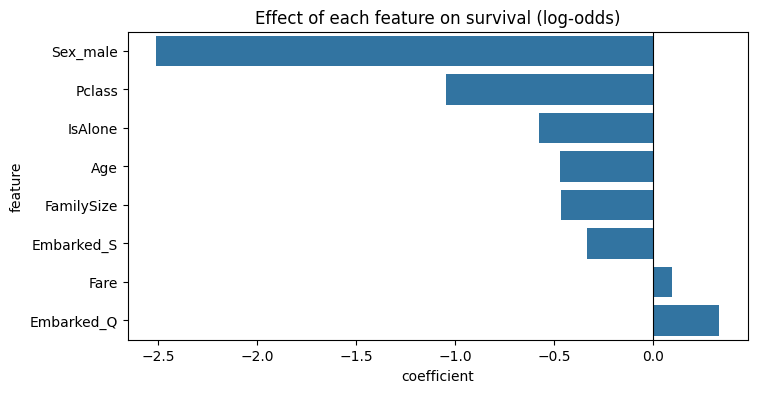

In [10]:
coef = pd.DataFrame({
    'feature': X_train_s.columns,
    'coefficient': model.coef_[0],
})
coef['odds_ratio'] = np.exp(coef['coefficient'])
coef = coef.sort_values('coefficient')

print('Intercept:', round(model.intercept_[0], 3))
print()
print(coef.round(3).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x='coefficient', y='feature', data=coef)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Effect of each feature on survival (log-odds)')
plt.show()

In [11]:
row = X_test_s.iloc[[0]]

z = (row.values[0] * model.coef_[0]).sum() + model.intercept_[0]
p_manual = 1 / (1 + np.exp(-z))
p_model = model.predict_proba(row)[0, 1]

print('Passenger features (scaled):')
print(row.round(2).to_string(index=False))
print()
print('z = sum(weight * feature) + intercept =', round(z, 4))
print('Sigmoid of z (by hand)                =', round(p_manual, 4))
print("model.predict_proba says              =", round(p_model, 4))

Passenger features (scaled):
 Pclass   Age  Fare  FamilySize  IsAlone  Sex_male  Embarked_Q  Embarked_S
      3 -0.43 -0.16         0.7        0         1           0           1

z = sum(weight * feature) + intercept = -2.1708
Sigmoid of z (by hand)                = 0.1024
model.predict_proba says              = 0.1024


In [12]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
for C in [0.01, 0.1, 1, 10, 100]:
    for cw in [None, 'balanced']:
        scores = cross_val_score(
            LogisticRegression(C=C, class_weight=cw, max_iter=1000),
            X_train_s, y_train, cv=cv, scoring='accuracy'
        )
        results.append({'C': C, 'class_weight': str(cw), 'cv_accuracy': scores.mean()})

res = pd.DataFrame(results).sort_values('cv_accuracy', ascending=False)
print(res.round(4).to_string(index=False))

best = res.iloc[0]
best_cw = None if best['class_weight'] == 'None' else 'balanced'
best_model = LogisticRegression(C=float(best['C']), class_weight=best_cw, max_iter=1000)
best_model.fit(X_train_s, y_train)

print()
print('Best settings: C =', best['C'], '| class_weight =', best_cw)
print('Original model test accuracy:', round(accuracy_score(y_test, model.predict(X_test_s)), 3))
print('Tuned model test accuracy   :', round(accuracy_score(y_test, best_model.predict(X_test_s)), 3))

     C class_weight  cv_accuracy
  0.10         None       0.8034
  1.00         None       0.7992
100.00         None       0.7992
 10.00         None       0.7992
  0.10     balanced       0.7978
 10.00     balanced       0.7894
100.00     balanced       0.7894
  1.00     balanced       0.7879
  0.01     balanced       0.7781
  0.01         None       0.7387

Best settings: C = 0.1 | class_weight = None
Original model test accuracy: 0.793
Tuned model test accuracy   : 0.793


In [13]:
def survival_probability(pclass, sex, age, fare, sibsp, parch, embarked):
    family = sibsp + parch + 1
    row = pd.DataFrame([{
        'Pclass': pclass,
        'Age': age,
        'Fare': fare,
        'FamilySize': family,
        'IsAlone': int(family == 1),
        'Sex_male': int(sex == 'male'),
        'Embarked_Q': int(embarked == 'Q'),
        'Embarked_S': int(embarked == 'S'),
    }])[X_train.columns]
    row[num_cols] = scaler.transform(row[num_cols])
    return model.predict_proba(row)[0, 1]


examples = [
    ('25-year-old man, 3rd class, travelling alone',      (3, 'male',   25,  7.9, 0, 0, 'S')),
    ('25-year-old woman, 1st class, travelling alone',    (1, 'female', 25, 80.0, 0, 0, 'C')),
    ('8-year-old girl, 2nd class, with her family of 4',  (2, 'female',  8, 30.0, 1, 2, 'S')),
    ('50-year-old man, 1st class, travelling alone',      (1, 'male',   50, 60.0, 0, 0, 'S')),
]

for label, args in examples:
    p = survival_probability(*args)
    print(f'{label:<52} -> P(survive) = {p:.2f}  ->', 'Survived' if p >= 0.5 else 'Died')

25-year-old man, 3rd class, travelling alone         -> P(survive) = 0.10  -> Died
25-year-old woman, 1st class, travelling alone       -> P(survive) = 0.95  -> Survived
8-year-old girl, 2nd class, with her family of 4     -> P(survive) = 0.84  -> Survived
50-year-old man, 1st class, travelling alone         -> P(survive) = 0.28  -> Died
